# Init

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt # type: ignore
import numpy as np # type: ignore
import pandas as pd

import gwadama
import clawdia.plotting

# Load already-computed data

In [2]:
# Strains clean
f = np.load('data/strains_clean.npz')
strains_clean = f['strains']
wave_pos_clean = f['wave_pos']


# Strains injected
f = np.load('data/strains_injected.npz')
strains_injected = f['strains']
lengths_injected = f['lengths']

# Dummy dataset

## Clean

In [3]:
SR = 2048
MAX_LENGTH = 2048

ds = gwadama.SyntheticWaves(
    classes={'SG': 1, 'G': 2, 'RD': 3},
    n_waves_per_class=5,
    wave_parameters_limits={
        'mf0': 100,   'Mf0': 200,
        'mQ': 10,    'MQ': 20,
        'mhrss': 1e-3, 'Mhrss': 1,
        'mT': 0.01,    'MT': 0.5
    },
    max_length=MAX_LENGTH,
    peak_time_max_length=0.5,
    amp_threshold=0.01,
    tukey_alpha=0.1,
    sample_rate=SR,
    random_seed=42
)

In [3]:
ds.metadata

,Class,f0,Q,hrss,duration
0,SG,170.0,13.0,0.376525,0.104492
1,SG,162.0,10.0,0.845020,0.083984
2,SG,169.0,17.0,0.002423,0.137695
3,SG,136.0,13.0,0.602969,0.130859
4,SG,156.0,18.0,0.021392,0.157227
5,G,NaN,NaN,0.004805,0.087891
6,G,NaN,NaN,0.001554,0.254883
7,G,NaN,NaN,0.078522,0.194336
8,G,NaN,NaN,0.011577,0.446289
9,G,NaN,NaN,0.477929,0.209961


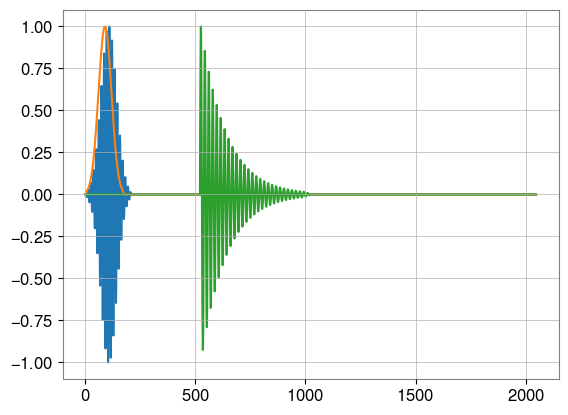

In [15]:
strains, lengths = ds.get_strains_array(length=MAX_LENGTH)

strains /= np.max(np.abs(strains), axis=1, keepdims=True)

fig, ax = plt.subplots()
ax.plot(strains[0])
ax.plot(strains[5])
ax.plot(strains[10])

In [5]:
wave_pos = np.zeros((len(strains), 2), dtype=int)

for i, strain in enumerate(strains):
    wave_pos[i, 0] = np.argmax(np.abs(strain) != 0)
    wave_pos[i, 1] = len(strain) - np.argmax(np.abs(strain[::-1]) != 0)

print(wave_pos)



np.savez_compressed(
    'data/strains_clean.npz',
    strains=strains,
    wave_pos=wave_pos
)

[[   1  213]
 [   1  171]
 [   1  281]
 [   1  267]
 [   1  321]
 [   1  179]
 [   1  521]
 [   1  397]
 [   1  913]
 [   1  429]
 [ 522 1041]
 [ 612 1221]
 [ 262  521]
 [ 339  675]
 [ 336  669]]


## Injected

In [4]:
dsi = gwadama.InjectedSyntheticWaves(
    ds,
    psd=np.loadtxt('data/noise_psd.txt', unpack=True),
    detector='ET',
    noise_length=8*MAX_LENGTH,
    freq_cutoff=20,
    freq_butter_order=5,
    random_seed=42
)

dsi.gen_injections(
    snr=15,
    pad=MAX_LENGTH//2,
    randomize_noise=True,
    random_seed=42,
    injections_per_snr=1,
    verbose=False
)

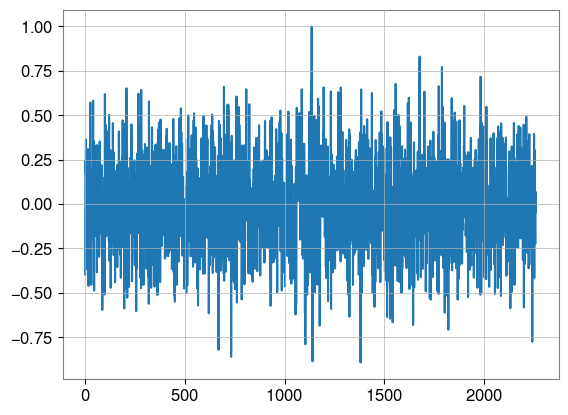

In [7]:
strains_injected, lengths_injected = dsi.get_strains_array()

strains_injected = strains_injected.copy()
strains_injected /= np.max(np.abs(strains_injected), axis=1, keepdims=True)

fig, ax = plt.subplots()
ax.plot(strains_injected[0,:lengths_injected[0]])

In [8]:
np.savez_compressed(
    'data/strains_injected.npz',
    strains=strains_injected,
    lengths=lengths_injected
)